In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score, mean_pinball_loss, d2_pinball_score, d2_absolute_error_score

In [2]:
# Load Data
df = pd.read_csv('JECC.csv')
print("\nData Saham (Head):\n", df.head())
print("\nData Saham (Tail):\n", df.tail())
print(f"\nJumlah baris awal: {len(df)}")


Data Saham (Head):
          timestamp  open   low  high  close  volume
0   4/16/2020 9:00  6950  6950  6950   6950       0
1  4/16/2020 10:00  6950  6950  6950   6950       0
2  4/16/2020 11:00  6950  6950  6950   6950       0
3  4/16/2020 12:00  6950  6950  6950   6950       0
4  4/16/2020 13:00  6950  6950  6950   6950       0

Data Saham (Tail):
              timestamp  open   low  high  close  volume
5542  12/30/2022 11:00     0     0     0      0       0
5543  12/30/2022 12:00     0     0     0      0       0
5544  12/30/2022 13:00  4890  4890  4890   4890     100
5545  12/30/2022 14:00     0     0     0      0       0
5546  12/30/2022 15:00  4940  4940  4940   4940    8300

Jumlah baris awal: 5547


In [3]:
# Pra-pemrosesan
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values(by='timestamp')
df['target'] = df['close'].shift(-1)
df = df.dropna()

In [4]:
df.shape

(5546, 7)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5546 entries, 0 to 5545
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  5546 non-null   datetime64[ns]
 1   open       5546 non-null   int64         
 2   low        5546 non-null   int64         
 3   high       5546 non-null   int64         
 4   close      5546 non-null   int64         
 5   volume     5546 non-null   int64         
 6   target     5546 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(5)
memory usage: 346.6 KB


In [6]:
df.describe()

,timestamp,open,low,high,close,volume,target
count,5546,5546.000000,5546.000000,5546.000000,5546.000000,5546.000000,5546.000000
mean,2021-08-14 12:35:08.470970112,5862.082582,5832.884962,5894.113776,5864.802560,136.999639,5864.440137
min,2020-04-16 09:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2020-12-15 11:15:00,4910.000000,4890.000000,4950.000000,4950.000000,0.000000,4942.500000
50%,2021-08-13 13:30:00,5950.000000,5950.000000,5950.000000,5950.000000,0.000000,5950.000000
75%,2022-04-13 15:45:00,6500.000000,6500.000000,6500.000000,6500.000000,0.000000,6500.000000
max,2022-12-30 14:00:00,9700.000000,9700.000000,10000.000000,10000.000000,45600.000000,10000.000000
std,NaN,999.684905,996.672524,1010.063700,1006.759518,1381.071817,1006.730577


In [7]:
df.isnull().sum()

timestamp    0
open         0
low          0
high         0
close        0
volume       0
target       0
dtype: int64

In [8]:
#Mengetahui nilai korelasi dari data.
df.corr()

,timestamp,open,low,high,close,volume,target
timestamp,1.000000,-0.704063,-0.711216,-0.682788,-0.690534,0.025104,-0.690511
open,-0.704063,1.000000,0.993233,0.990570,0.986325,-0.027717,0.972164
low,-0.711216,0.993233,1.000000,0.983505,0.990957,-0.032953,0.975773
high,-0.682788,0.990570,0.983505,1.000000,0.993232,-0.014536,0.977172
close,-0.690534,0.986325,0.990957,0.993232,1.000000,-0.019535,0.982888
volume,0.025104,-0.027717,-0.032953,-0.014536,-0.019535,1.000000,-0.017942
target,-0.690511,0.972164,0.975773,0.977172,0.982888,-0.017942,1.000000


In [9]:
# Buat variabel x(Label/Fitur) dan y (Target) 
x = df[["open", "low", "high", "close", "volume"]]
y = df["target"]

In [10]:
# Skenario pertama, bagi dataset menjadi 80% dan 20% untuk dilatih dan diuji
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [11]:
# Buat dan Latih Model Linear Regression
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [12]:
# Prediksi dan Evaluasi 
pred = model.predict(x_test)

mse = mean_squared_error(y_test, pred)
mae = mean_absolute_error(y_test,pred)
rmse =np.sqrt(mse)
rmae = np.sqrt(mae)
r2 = r2_score(y_test, pred)

evs = explained_variance_score(y_test, pred)
mpl = mean_pinball_loss(y_test, pred)
d2ps = d2_pinball_score(y_test, pred)
d2aes = d2_absolute_error_score(y_test, pred)

print(f"Mean Squared Error (MSE): %f" % (mse))
print(f"Mean Absolute Error (MAE): %f" % (mae))
print(f"RMSE: %f" % (rmse))
print(f"RMAE: %f" % (rmae))
print(f"R2 Score: %f" % (r2))

print(f"Explained Variance Score: %f" % (evs))
print(f"Mean Pinball Loss: %f" % (mpl))
print(f"D2 Pinball Score: %f" % (d2ps))
print(f"D2 Absolute Error Score: %f" % (d2aes))

Mean Squared Error (MSE): 38948.671624
Mean Absolute Error (MAE): 43.682338
RMSE: 197.354178
RMAE: 6.609262
R2 Score: 0.964173
Explained Variance Score: 0.964173
Mean Pinball Loss: 21.841169
D2 Pinball Score: 0.945946
D2 Absolute Error Score: 0.945946


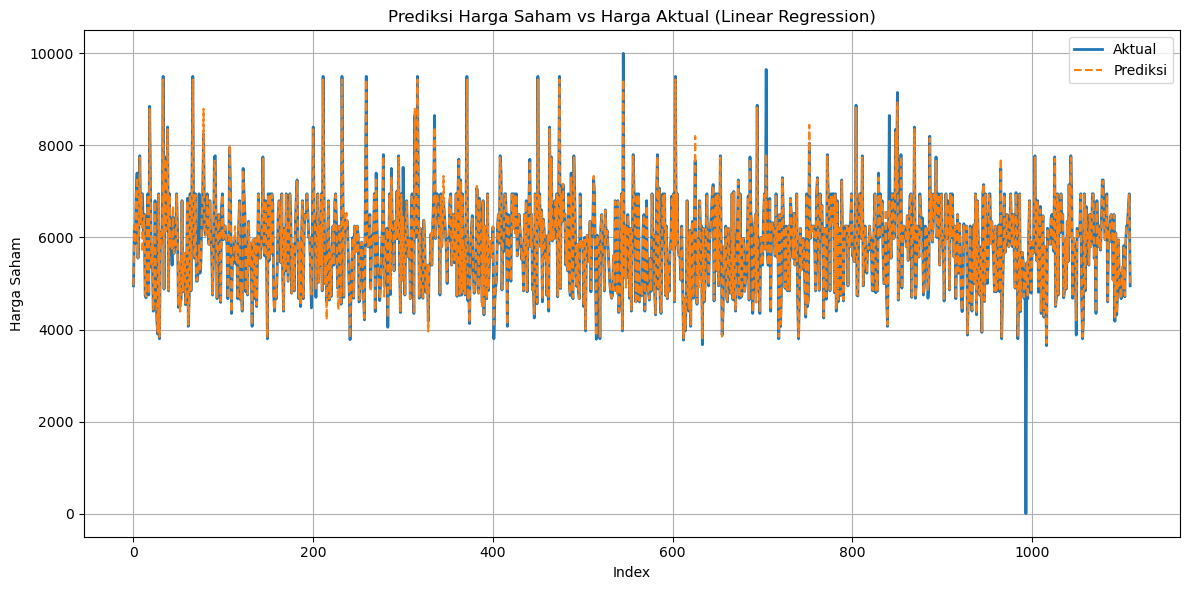

In [13]:
# 7. Visualisasi Prediksi vs Aktual
plt.figure(figsize=(12, 6))
plt.plot(y_test.values, label='Aktual', linewidth=2)
plt.plot(pred, label='Prediksi', linestyle='--')
plt.title('Prediksi Harga Saham vs Harga Aktual (Linear Regression)')
plt.xlabel('Index')
plt.ylabel('Harga Saham')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# Nilai slope/koefisien (m) dan intercept (b)
print(model.coef_)
print(model.intercept_)

[ 0.08624188  0.03753182 -0.01538429  0.87240254  0.00147573]
113.93582499302647


In [15]:
#Accuracy score dari model kita menggunakan testing data yang sudah displit sebelumnya.
model.score(x_test, y_test)

0.9641729544519343

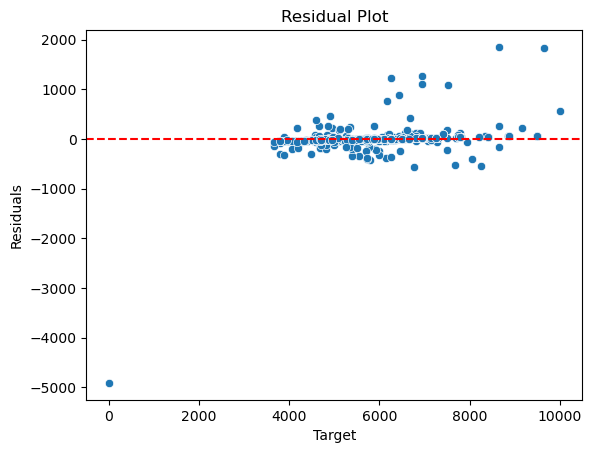

In [16]:
# Residual Plot
residuals = y_test - pred
sns.scatterplot(x=y_test,y=residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Target")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

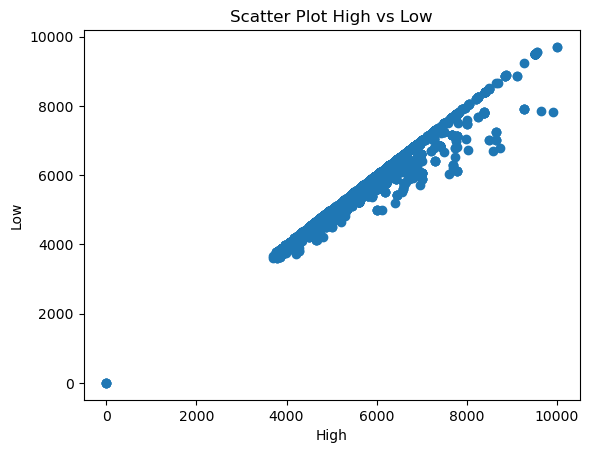

In [17]:
#Visualisasi scatter plot dari dataset (High vs Low).
plt.scatter(df['high'], df['low'])
plt.xlabel('High')
plt.ylabel('Low')
plt.title('Scatter Plot High vs Low')
plt.show()

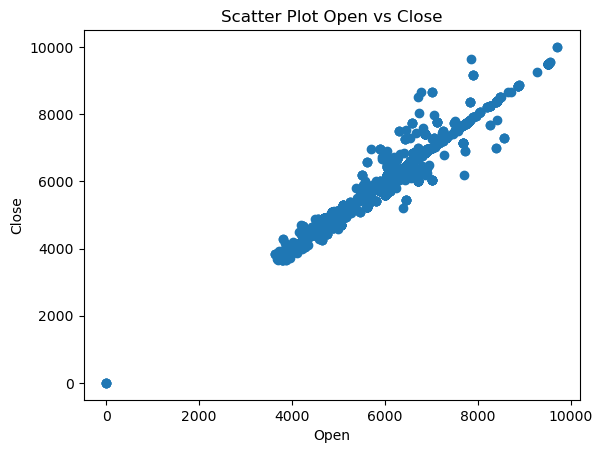

In [18]:
#Visualisasi scatter plot dari dataset (Open vs Close).
plt.scatter(df['open'], df['close'])
plt.xlabel('Open')
plt.ylabel('Close')
plt.title('Scatter Plot Open vs Close')
plt.show()

In [19]:
# Baseline: harga berikutnya = harga sekarang
mean_absolute_error(y_test, x_test['close'])
r2_score(y_test, x_test['close'])

# Split kronologis (data sudah diurutkan menurut timestamp)
n = int(len(x) * 0.8)
model.fit(x.iloc[:n], y.iloc[:n])
pred = model.predict(x.iloc[n:])
r2_score(y.iloc[n:], pred)

0.5031162948737912